# Diaphorina citri en red: un recorrido rápido

Demo para discusión con el asesor. Orden: Red -> Función -> Evolución -> Resultados -> Comparación.

## 0. Funciones necesarias

Solo lo que usamos aquí: el modelo de un nodo (para comparar), el generador de topologías, y el solver de red.

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

from functions import solve_system
from network_experiments import make_topology, solve_network_data, node_if, x1
from network_stability import master_lyapunov_spectrum
from network_experiments import laplacian

%matplotlib inline

## 1. Red -- la topología

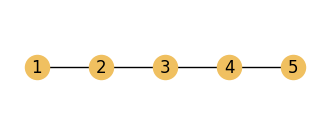

In [2]:
n = 5
graph = make_topology("Path", n)
fig, ax = plt.subplots(figsize=(4, 1.5))
nx.draw(graph, pos={i: (i, 0) for i in graph}, labels={i: i + 1 for i in graph},
        node_color="#f0c060", ax=ax)

## 2. Función -- el modelo en cada nodo

Mismos parámetros y ecuaciones del paper de un solo nodo, replicados en cada localidad. Diaphorina citri (x1) y Tamarixia radiata (x3) pueden moverse entre nodos vecinos (tasas Dd, Dt); brotes (x2) y vigor de planta (x4) se quedan en su nodo.

In [3]:
as_, cs = 0.000555, 0.005
param1 = [-0.2, 0.04, -0.01, as_, cs]
param2 = [-0.72, -0.01, 0.054, as_, cs]
param3 = [-0.3, 0.01, as_, cs]
param4 = [0.72, -0.072, as_, cs]
params = [param1, param2, param3, param4]

## 3. Evolución -- resolver el sistema

Un brote puntual: el nodo 1 arranca con 200 Diaphorina (foco), el resto en 20. Liberación periódica de Tamarixia (δ=35 cada T=15) en todos los nodos. Difusión Dd=Dt=0.03.

In [4]:
tt = 100
ics = [[200] + [20] * (n - 1), [10] * n, [15] * n, [30] * n, tt]
netData = solve_network_data(graph, 0.03, 0.03, 35, 15, params, ics)
ts = np.linspace(0, tt, 1001)

## 4. Resultados -- ¿qué pasó en cada nodo?

Diaphorina citri (x1) en cada nodo a lo largo del tiempo. El nodo 1 (el foco del brote) parte muy por encima del resto.

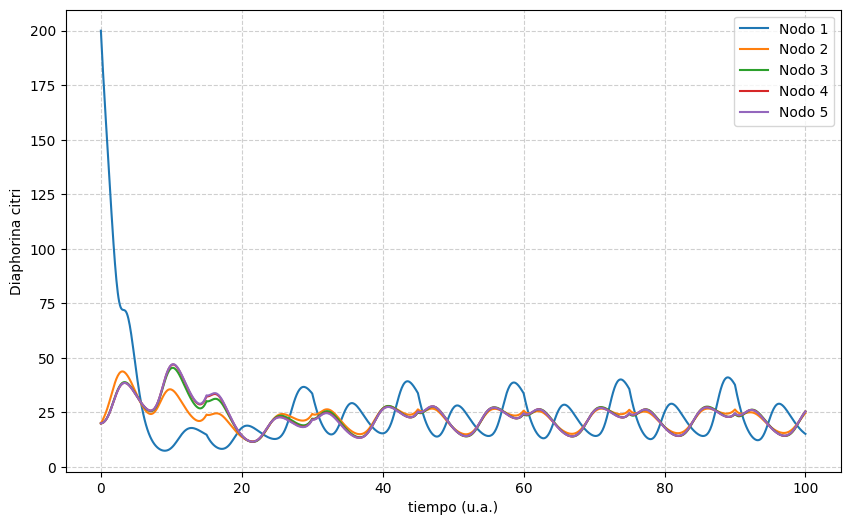

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
for i in range(n):
    ax.plot(ts, node_if(netData, x1, i)(ts), label=f"Nodo {i + 1}")
ax.set_xlabel("tiempo (u.a.)"); ax.set_ylabel("Diaphorina citri")
ax.grid(True, linestyle="--", alpha=0.6); ax.legend();

## 5. Comparación: ¿importó la red?

(a) El nodo 1 en la red, contra el mismo huerto aislado (modelo de un solo nodo, misma condición inicial). La diferencia es exactamente el efecto de estar conectado.

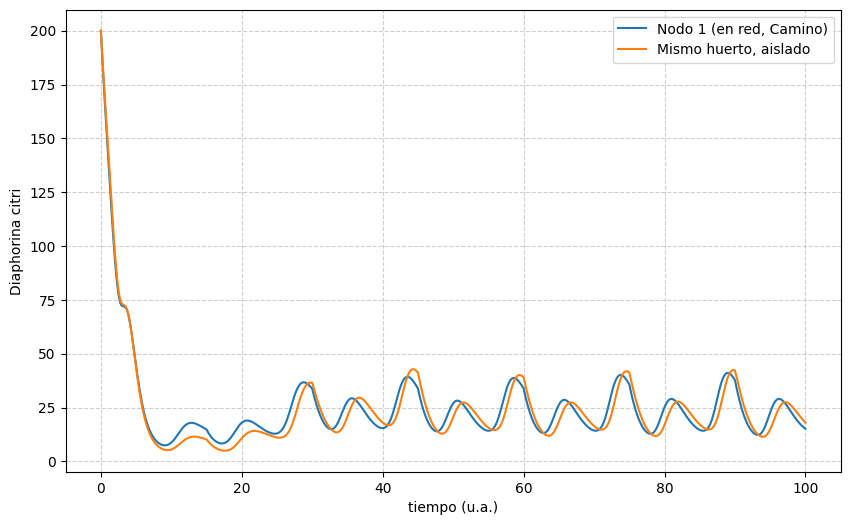

In [6]:
singleSol = solve_system(35, 15, params, [200, 10, 15, 30, tt])
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(ts, node_if(netData, x1, 0)(ts), label="Nodo 1 (en red, Camino)")
ax.plot(ts, singleSol(ts)[0], label="Mismo huerto, aislado")
ax.set_xlabel("tiempo (u.a.)"); ax.set_ylabel("Diaphorina citri")
ax.grid(True, linestyle="--", alpha=0.6); ax.legend();

(b) La misma pregunta, pero cambiando solo la topología: Camino (poco conectada) contra Completa (todos los nodos conectados entre sí).

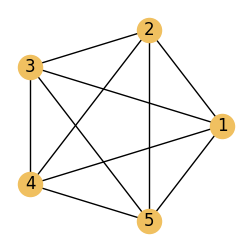

In [7]:
graphComplete = make_topology("Complete", n)
fig, ax = plt.subplots(figsize=(3, 3))
nx.draw_circular(graphComplete, labels={i: i + 1 for i in graphComplete}, node_color="#f0c060", ax=ax)

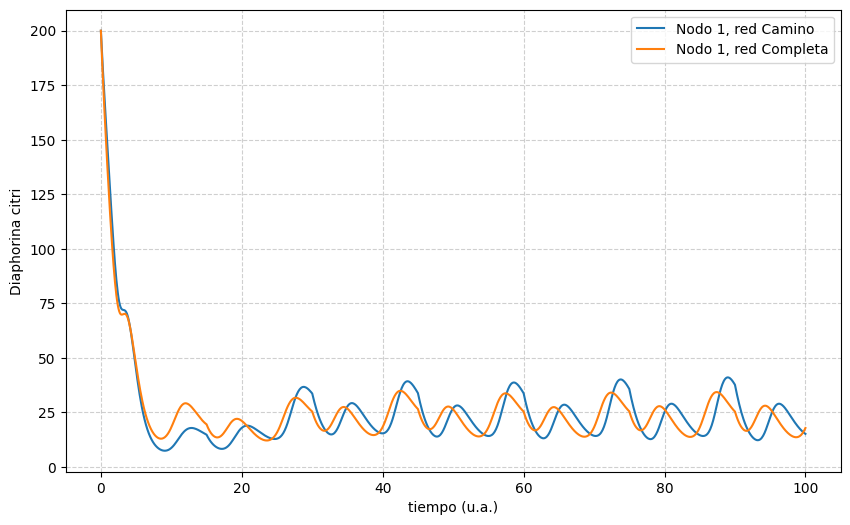

In [8]:
netDataComplete = solve_network_data(graphComplete, 0.03, 0.03, 35, 15, params, ics)
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(ts, node_if(netData, x1, 0)(ts), label="Nodo 1, red Camino")
ax.plot(ts, node_if(netDataComplete, x1, 0)(ts), label="Nodo 1, red Completa")
ax.set_xlabel("tiempo (u.a.)"); ax.set_ylabel("Diaphorina citri")
ax.grid(True, linestyle="--", alpha=0.6); ax.legend();

## 6. Contención de brote por topología

Repetimos el mismo brote y calendario de liberación en distintas topologías, comparando la densidad promedio de Diaphorina en el nodo 1 (t=50 a 100).

[23.283768031425467, 22.50310784777725, 22.503107847777255, 23.135845749191585]


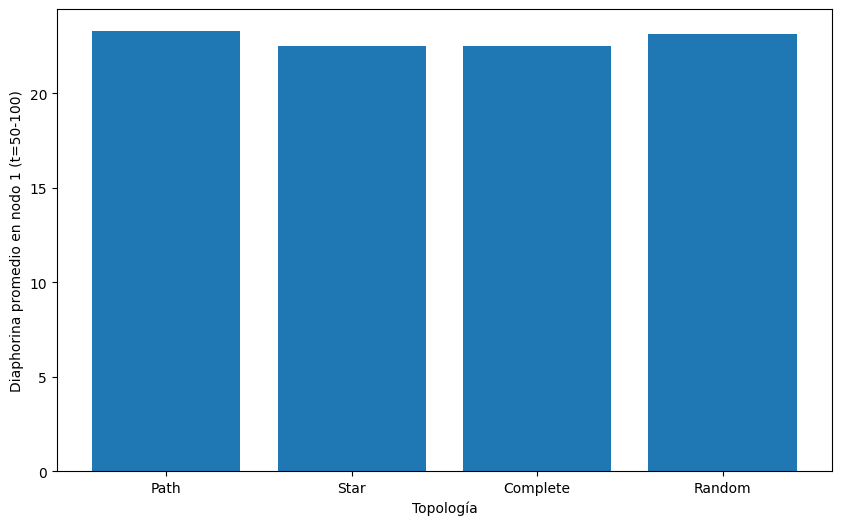

In [9]:
topologiasDemo = ["Path", "Star", "Complete", "Random"]

def media_nodo1(nd):
    return nd["Solution"].integrate(50, 100, 0) / 50   # fila 0 = x1 del nodo 1

contencion = [media_nodo1(solve_network_data(make_topology(topo, n), 0.03, 0.03, 35, 15, params, ics))
              for topo in topologiasDemo]
print(contencion)
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(topologiasDemo, contencion)
ax.set_xlabel("Topología"); ax.set_ylabel("Diaphorina promedio en nodo 1 (t=50-100)");

## 7. Dosis y frecuencia -- mini comparación

Misma red (Camino), dos calendarios de liberación: el baseline (δ=35 cada T=15) contra uno más frecuente y suave (δ=15 cada T=7).

[23.283768031425467, 22.34548175853096]


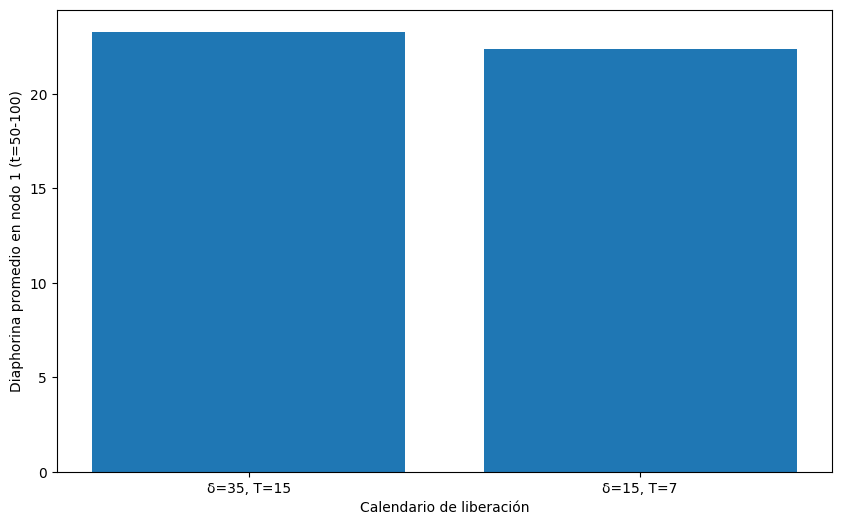

In [10]:
calendarios = [(35, 15), (15, 7)]
dosisComparacion = [media_nodo1(solve_network_data(graph, 0.03, 0.03, d, T, params, ics))
                    for d, T in calendarios]
print(dosisComparacion)
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(["δ=35, T=15", "δ=15, T=7"], dosisComparacion)
ax.set_xlabel("Calendario de liberación"); ax.set_ylabel("Diaphorina promedio en nodo 1 (t=50-100)");

## 8. Sensibilidad a un parámetro

Perturbamos el vigor de planta (r4) ±10% para ver qué tan sensible es el resultado.

[18.346638288262028, 23.283768031425467, 24.48668724414632]


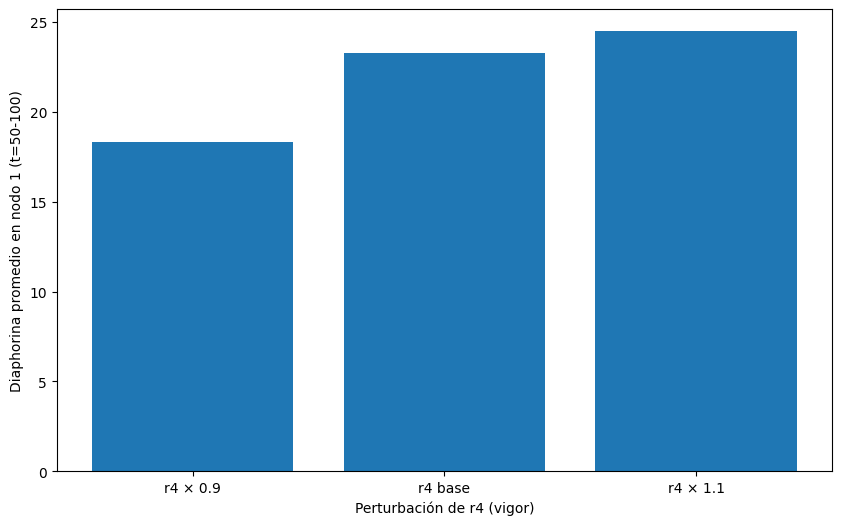

In [11]:
import copy
r4Base = param4[0]
sensibilidadR4 = []
for factor in (0.9, 1.0, 1.1):
    paramsMod = copy.deepcopy(params)
    paramsMod[3][0] = r4Base * factor
    sensibilidadR4.append(media_nodo1(solve_network_data(graph, 0.03, 0.03, 35, 15, paramsMod, ics)))
print(sensibilidadR4)
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(["r4 × 0.9", "r4 base", "r4 × 1.1"], sensibilidadR4)
ax.set_xlabel("Perturbación de r4 (vigor)"); ax.set_ylabel("Diaphorina promedio en nodo 1 (t=50-100)");

## 9. Estabilidad de sincronización

Usamos la librería de estabilidad ya construida (network_stability.py): en cada modo espacial de esta red Camino, un exponente de Lyapunov negativo significa que las diferencias entre nodos se apagan con el tiempo.

[0.0011135541987618305, -0.002285495302324706, -0.0042895533243801085, -0.0069795143438143034]


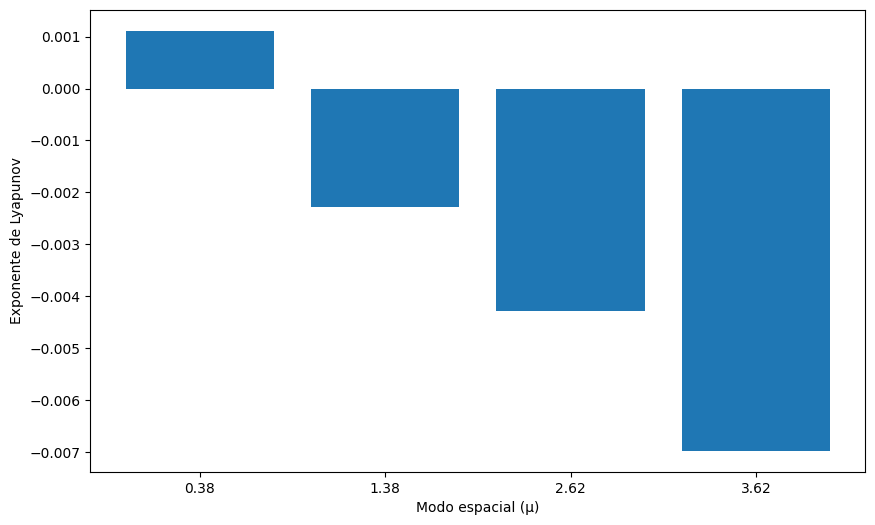

In [12]:
modosTransversales = np.sort(np.linalg.eigvalsh(laplacian(graph)))[1:]
espectro = master_lyapunov_spectrum(params, 0.03, 0.03, modosTransversales, 35, 15)
lams = [e["LyapunovExponent"] for e in espectro]
print(lams)
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar([f"{m:.2f}" for m in modosTransversales], lams)
ax.set_xlabel("Modo espacial (μ)"); ax.set_ylabel("Exponente de Lyapunov");